# Trabalho Prático 3: Exploração e Mapeamento com Occupancy Grid

**Disciplina:** Robótica Móvel — 2º Semestre de 2026  
**Professor:** Prof. Douglas G. Macharet — DCC / UFMG  
**Aluno:** Isaac Reyes  
**Ambiente:** Python 3.13 gerenciado via UV, CoppeliaSim Edu 4.10 (executando em container com GPU dedicada NVIDIA RTX 3050)

---

## 1. Introdução e Formulação Teórica

O objetivo deste trabalho prático é implementar o algoritmo de **Occupancy Grid Mapping** (Mapeamento em Grades de Ocupação) em conjunto com uma estratégia reativa de **navegação e exploração autônoma** para um robô diferencial **Kobuki** equipado com um sensor laser planar **fastHokuyo**.

O algoritmo de grade de ocupação divide o ambiente contínuo 2D em uma malha discreta de células regulares $m = \{m_i\}$. Cada célula armazena uma variável aleatória binária indicando se está **ocupada** ($m_i = 1$) ou **livre** ($m_i = 0$).

### 1.1 Modelo Log-Odds

A probabilidade de ocupação $p(m_i)$ é representada em forma de **log-odds** (razão de probabilidades logarítmica) para evitar instabilidades numéricas e permitir atualizações aditivas simples:

$$l(m_i) = \ln \left( \frac{p(m_i)}{1 - p(m_i)} \right)$$

Para um prior neutro $p_0 = 0.5$, o log-odds inicial é $l_0 = \ln(0.5 / 0.5) = 0$.
A cada nova leitura sensorial $z_t$, a equação de atualização bayesiana de cada célula é:

$$l_{t}(m_i) = l_{t-1}(m_i) + \text{inv\_sensor\_model}(m_i, x_t, z_t) - l_0$$

Onde:
- Células no trajeto do raio laser (espaço livre) recebem incremento negativo: $l_{free} = \ln \left( \frac{p_{free}}{1 - p_{free}} \right)$ com $p_{free} = 0.40$.
- A célula onde ocorreu o impacto com o obstáculo recebe incremento positivo: $l_{occ} = \ln \left( \frac{p_{occ}}{1 - p_{occ}} \right)$ com $p_{occ} = 0.85$.

A recuperação da probabilidade final a partir do log-odds é dada pela função sigmoide:

$$p(m_i) = 1 - \frac{1}{1 + \exp(l(m_i))}$$

### 1.2 Transformações de Coordenadas e Discretização

O robô possui pose conhecida no referencial global (mundo) $(x_r, y_r, \theta_r)$. O sensor laser está montado coaxialmente no referencial do robô. Para um feixe laser com ângulo relativo $\theta_i$ e alcance medido $d_i$:

$$\begin{bmatrix} x_w \\ y_w \end{bmatrix} = \begin{bmatrix} x_r \\ y_r \end{bmatrix} + \begin{bmatrix} \cos(\theta_r + \theta_i) & -\sin(\theta_r + \theta_i) \\ \sin(\theta_r + \theta_i) & \cos(\theta_r + \theta_i) \end{bmatrix} \begin{bmatrix} d_i \\ 0 \end{bmatrix} = \begin{bmatrix} x_r + d_i \cos(\theta_r + \theta_i) \\ y_r + d_i \sin(\theta_r + \theta_i) \end{bmatrix}$$

A discretização contínuo $\to$ discreto mapeia as coordenadas do mundo $(x_w, y_w)$ para índices inteiros de coluna e linha da matriz $(c_x, c_y)$:

$$c_x = \left\lfloor \frac{x_w - x_{min}}{\Delta} \right\rfloor, \quad c_y = \left\lfloor \frac{y_w - y_{min}}{\Delta} \right\rfloor$$

onde $\Delta$ é o tamanho da célula (resolução espacial da grade).

O traçado dos raios no espaço livre é computado de forma exata e eficiente utilizando o **Algoritmo de Linha de Bresenham** 2D.

In [1]:
# Configuração de caminhos, imports e verificação do ambiente
import os
import sys
import time
import matplotlib.pyplot as plt
import numpy as np
from coppeliasim_zmqremoteapi_client import RemoteAPIClient

# Garantindo resolução do root do projeto
project_root = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
if project_root not in sys.path:
    sys.path.insert(0, os.path.join(project_root, "src"))

results_dir = os.path.join(project_root, "results")

# Importando módulos desenvolvidos no projeto src/tp3
from tp3.robot import KobukiRobot
from tp3.occupancy_grid import OccupancyGrid, bresenham_line
from tp3.navigator import ReactiveNavigator
from tp3.simulation import run_exploration, plot_exploration_results

print(f"Project root: {project_root}")
print(f"Results dir: {results_dir}")
print("Módulos do TP3 carregados com sucesso!")

Project root: /home/pollo/Documents/dcc/rob/tp3
Results dir: /home/pollo/Documents/dcc/rob/tp3/results
Módulos do TP3 carregados com sucesso!


## 2. Conexão com o Simulador CoppeliaSim e Modelo Cinemático

O robô Kobuki é acionado diferencialmente com:
- Raio da roda: $r = 0.035$ m
- Distância entre rodas (baseline): $L = 0.230$ m

Dadas a velocidade linear desejada $v$ e a velocidade angular $\omega$, as velocidades angulares das rodas esquerda e direita são:

$$\omega_{left} = \frac{v - \frac{\omega L}{2}}{r}, \quad \omega_{right} = \frac{v + \frac{\omega L}{2}}{r}$$

O sensor laser `fastHokuyo` fornece 684 feixes cobrindo um campo de visão de $180^\circ$ ($-\pi/2$ a $+\pi/2$). Os dados são recuperados em formato binário compacto através de `sim.getBufferSignal` e desempacotados via `sim.unpackFloatTable`.

In [2]:
# Conectando ao CoppeliaSim na porta 23000
client = RemoteAPIClient()
sim = client.require("sim")
print(f"Conectado ao CoppeliaSim! Sim time: {sim.getSimulationTime():.2f}s")

# Carregando cena estática para validação
scene_path = "/workspace/cenas/cena-tp3-estatico.ttt"
sim.loadScene(scene_path)
robot = KobukiRobot(sim=sim)
x, y, yaw = robot.get_pose()
print(f"Pose inicial do robô: x={x:.3f}m, y={y:.3f}m, yaw={yaw:.3f} rad")
print(f"Parâmetros cinemáticos: L={robot.WHEEL_BASE}m, r={robot.WHEEL_RADIUS}m, Alcance Laser Máx={robot.MAX_LASER_RANGE}m")

Conectado ao CoppeliaSim! Sim time: 0.00s


Pose inicial do robô: x=-4.000m, y=-4.000m, yaw=-0.000 rad
Parâmetros cinemáticos: L=0.23m, r=0.035m, Alcance Laser Máx=5.0m


## 3. Avaliação 1: Impacto do Tamanho da Célula (0.01m, 0.10m, 0.50m)

Conforme exigido nas instruções do TP3, avaliamos 3 diferentes valores de resolução espacial da grade no cenário estático:
1. **Célula de 0.01 m (1 cm)**: Alta resolução espacial ($1100 \times 1100$ células). Detalha perfeitamente contornos, pernas de cadeiras e pequenas quinas, porém exige maior consumo de memória e traçado de raios mais denso.
2. **Célula de 0.10 m (10 cm)**: Resolução intermediária balanceada ($110 \times 110$ células). Produz paredes sólidas, delimita claramente obstáculos (sofás, mesas e pilares) e filtra ruídos de medição com baixo custo computacional. **Definido como o melhor valor para os experimentos subsequentes**.
3. **Célula de 0.50 m (50 cm)**: Baixa resolução ($22 \times 22$ células). Obstáculos e paredes tornam-se blocos excessivamente espessos, pernas de cadeiras mesclam-se em massas contínuas e corredores estreitos parecem bloqueados.

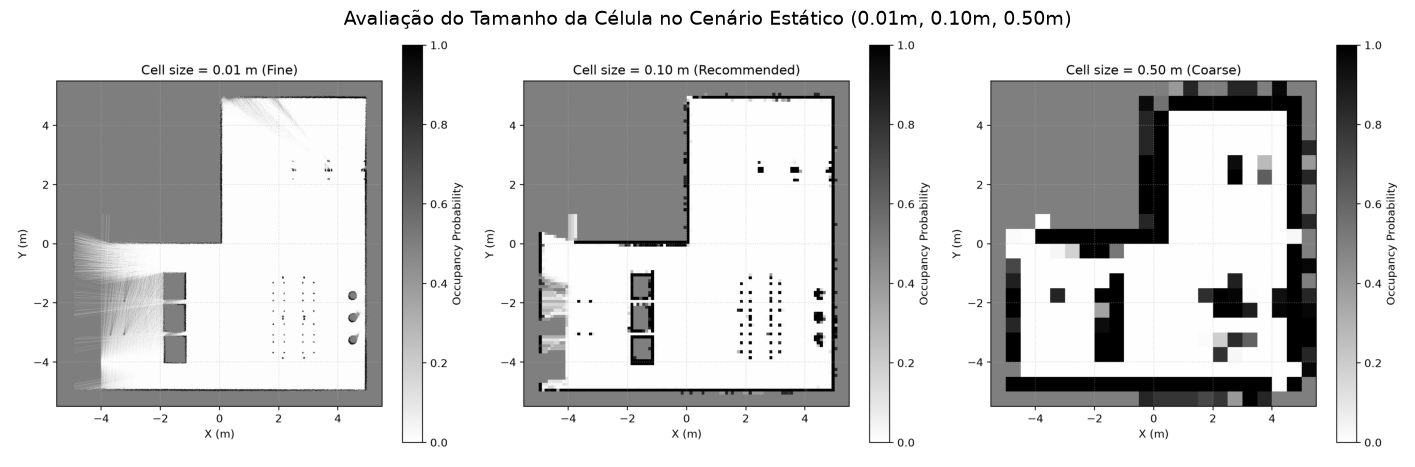

In [3]:
# Exibindo a comparação direta dos 3 mapas gerados para o mesmo trajeto
comp_path = os.path.join(results_dir, "exp1_cell_size_comparison.png")
comparison_img = plt.imread(comp_path)
plt.figure(figsize=(18, 6))
plt.imshow(comparison_img)
plt.axis("off")
plt.title("Avaliação do Tamanho da Célula no Cenário Estático (0.01m, 0.10m, 0.50m)", fontsize=14)
plt.show()

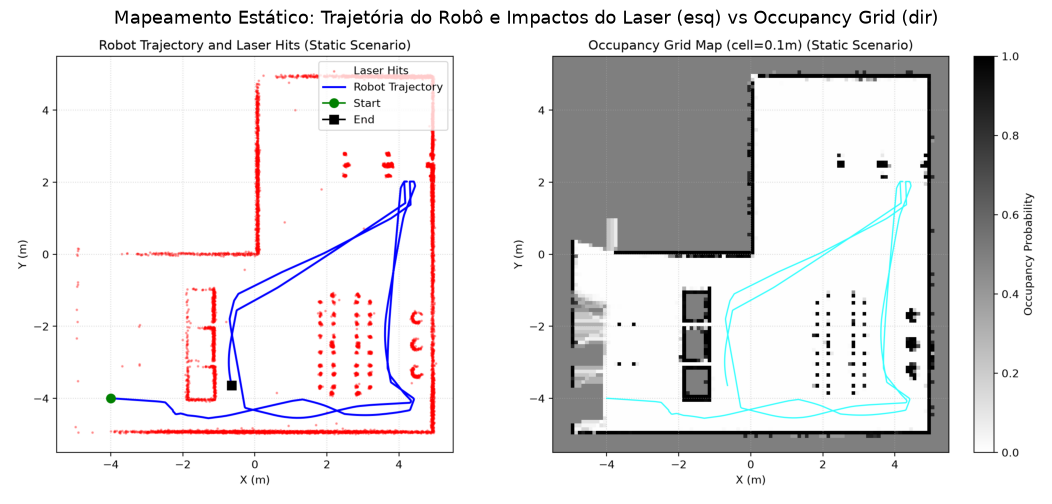

In [4]:
# Visão geral do mapeamento no Cenário Estático com cell=0.10m (Trajetória + Pontos Laser vs Occupancy Grid)
overview_path = os.path.join(results_dir, "exp1_static_overview.png")
overview_img = plt.imread(overview_path)
plt.figure(figsize=(15, 6))
plt.imshow(overview_img)
plt.axis("off")
plt.title("Mapeamento Estático: Trajetória do Robô e Impactos do Laser (esq) vs Occupancy Grid (dir)", fontsize=13)
plt.show()

## 4. Avaliação 2: Cenário Estático com Diferentes Posições Iniciais

Com a melhor resolução definida ($0.10$ m), realizamos dois experimentos completos com **posições iniciais distintas** no cenário estático:
- **Experimento 2.1:** Posição inicial no canto inferior esquerdo: $(-4.0, -4.0)$ m, orientada ao longo do eixo $+X$.
- **Experimento 2.2:** Posição inicial no quadrante superior direito: $(3.0, 3.0)$ m, orientada para a esquerda.

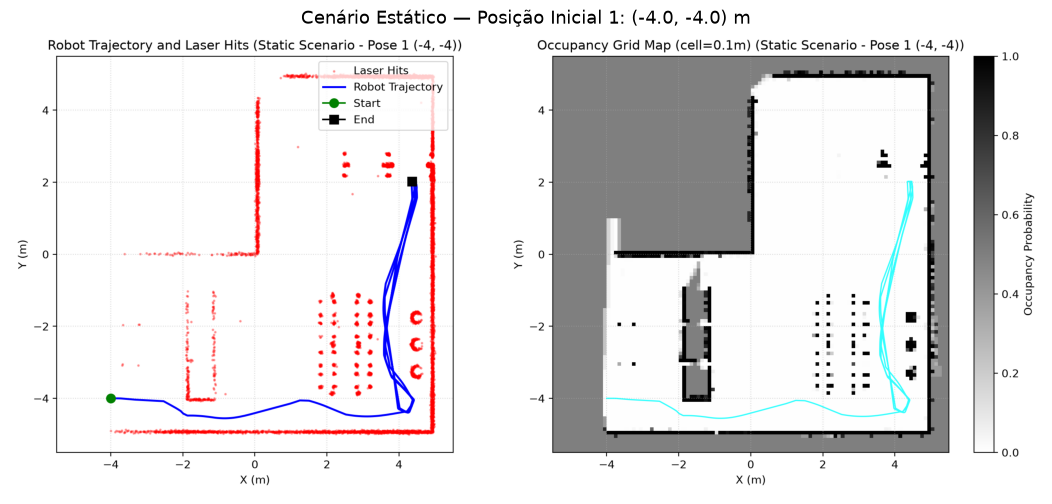

In [5]:
# Exibindo resultados do Cenário Estático - Pose 1 (-4, -4)
pos1_path = os.path.join(results_dir, "exp2_static_pos1_overview.png")
img_static_pos1 = plt.imread(pos1_path)
plt.figure(figsize=(15, 6))
plt.imshow(img_static_pos1)
plt.axis("off")
plt.title("Cenário Estático — Posição Inicial 1: (-4.0, -4.0) m", fontsize=13)
plt.show()

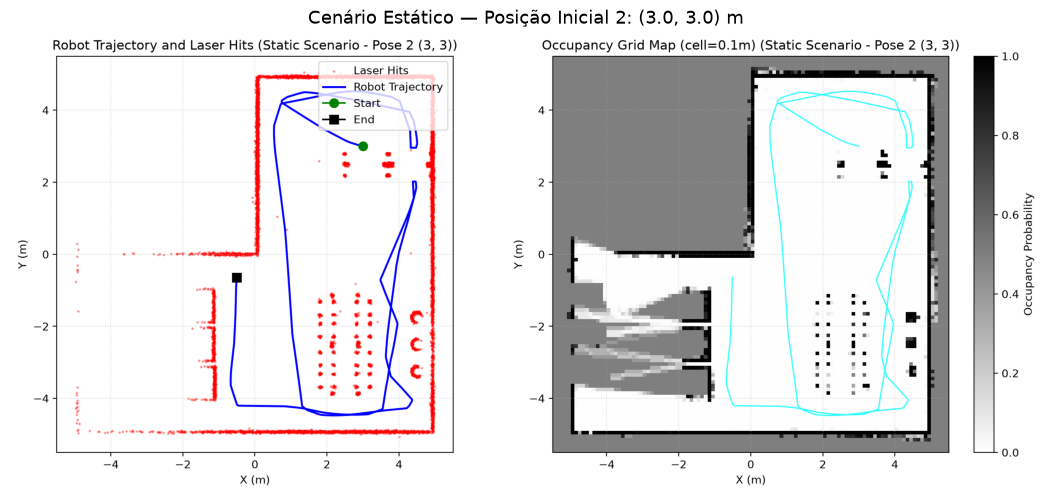

In [6]:
# Exibindo resultados do Cenário Estático - Pose 2 (3, 3)
pos2_path = os.path.join(results_dir, "exp3_static_pos2_overview.png")
img_static_pos2 = plt.imread(pos2_path)
plt.figure(figsize=(15, 6))
plt.imshow(img_static_pos2)
plt.axis("off")
plt.title("Cenário Estático — Posição Inicial 2: (3.0, 3.0) m", fontsize=13)
plt.show()

## 5. Avaliação 3: Cenário Dinâmico com Obstáculo Móvel (Bill)

No cenário dinâmico (`cena-tp3-dinamico.ttt`), existe um obstáculo móvel (o personagem humano Bill) caminhando pelo ambiente ao longo de uma rota pré-programada.

O algoritmo clássico de Occupancy Grid assume que o ambiente é estático. A presença de um agente dinâmico introduz fenômenos característicos:
1. **Rastros transitórios:** Conforme o humano caminha, leituras pontuais incrementam as células por onde ele passa.
2. **Limpeza por varredura posterior:** Quando o robô revisita ou mantém o feixe apontado para a região livre deixada pelo humano, as atualizações de espaço livre ($l_{free}$) reduzem progressivamente a probabilidade de ocupação das células transitórias, demonstrando a recuperação do filtro bayesiano.

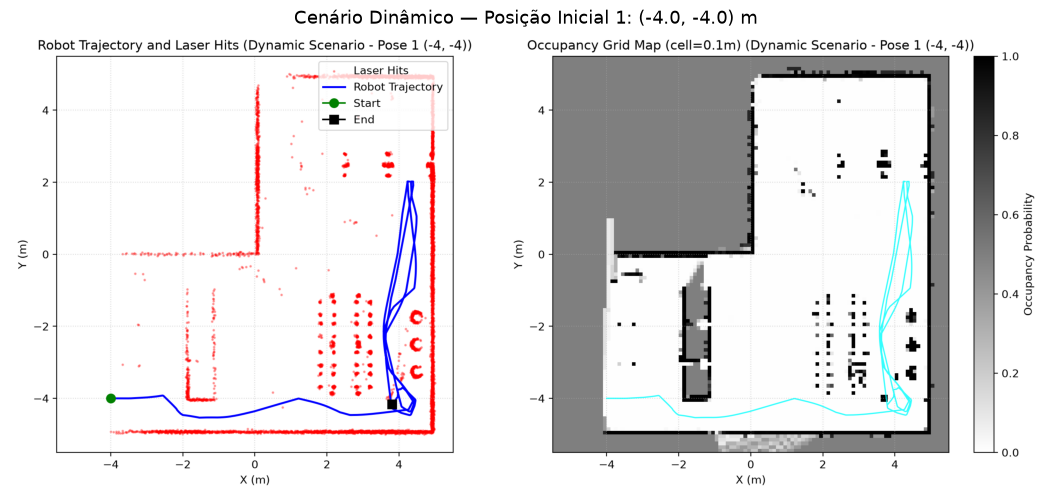

In [7]:
# Exibindo resultados do Cenário Dinâmico - Pose 1 (-4, -4)
dyn1_path = os.path.join(results_dir, "exp4_dynamic_pos1_overview.png")
img_dyn_pos1 = plt.imread(dyn1_path)
plt.figure(figsize=(15, 6))
plt.imshow(img_dyn_pos1)
plt.axis("off")
plt.title("Cenário Dinâmico — Posição Inicial 1: (-4.0, -4.0) m", fontsize=13)
plt.show()

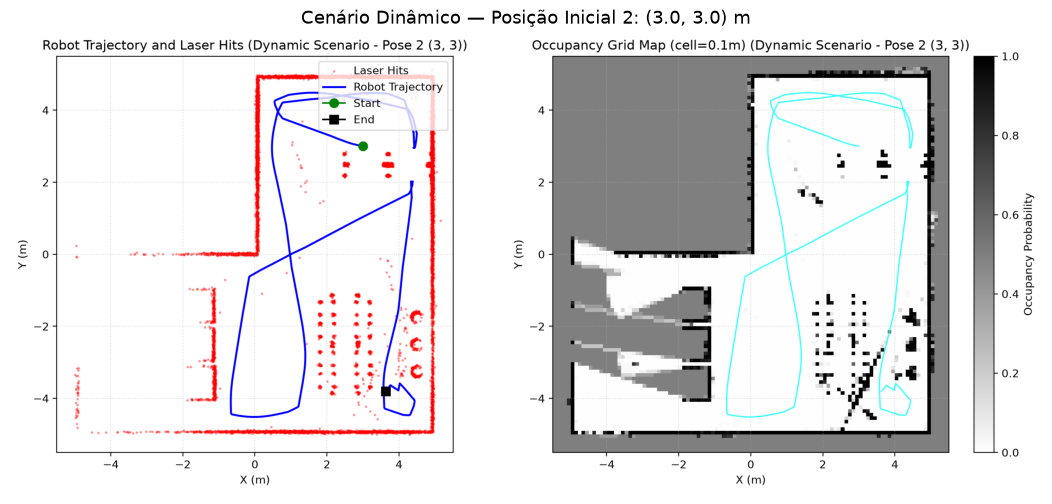

In [8]:
# Exibindo resultados do Cenário Dinâmico - Pose 2 (3, 3)
dyn2_path = os.path.join(results_dir, "exp5_dynamic_pos2_overview.png")
img_dyn_pos2 = plt.imread(dyn2_path)
plt.figure(figsize=(15, 6))
plt.imshow(img_dyn_pos2)
plt.axis("off")
plt.title("Cenário Dinâmico — Posição Inicial 2: (3.0, 3.0) m", fontsize=13)
plt.show()

## 6. Avaliação 4: Impacto do Ruído Sensorial no Mapeamento

Conforme orientado no enunciado, avaliamos o efeito da adição de ruído gaussiano aleatório nas leituras do laser (distância medida e ângulo de leitura):
- **Baixo Ruído:** $\sigma_r = 0.01$ m (1 cm), $\sigma_\theta = 0.002$ rad.
- **Médio Ruído:** $\sigma_r = 0.05$ m (5 cm), $\sigma_\theta = 0.010$ rad.
- **Alto Ruído:** $\sigma_r = 0.15$ m (15 cm), $\sigma_\theta = 0.030$ rad.

O modelo probabilístico de log-odds com saturação demonstra robustez contra ruídos moderados (5 cm), convergindo a geometria dos obstáculos à medida que múltiplas observações se acumulam. Sob ruído severo (15 cm), observa-se espessamento das bordas das paredes e dispersão nas fronteiras dos móveis.

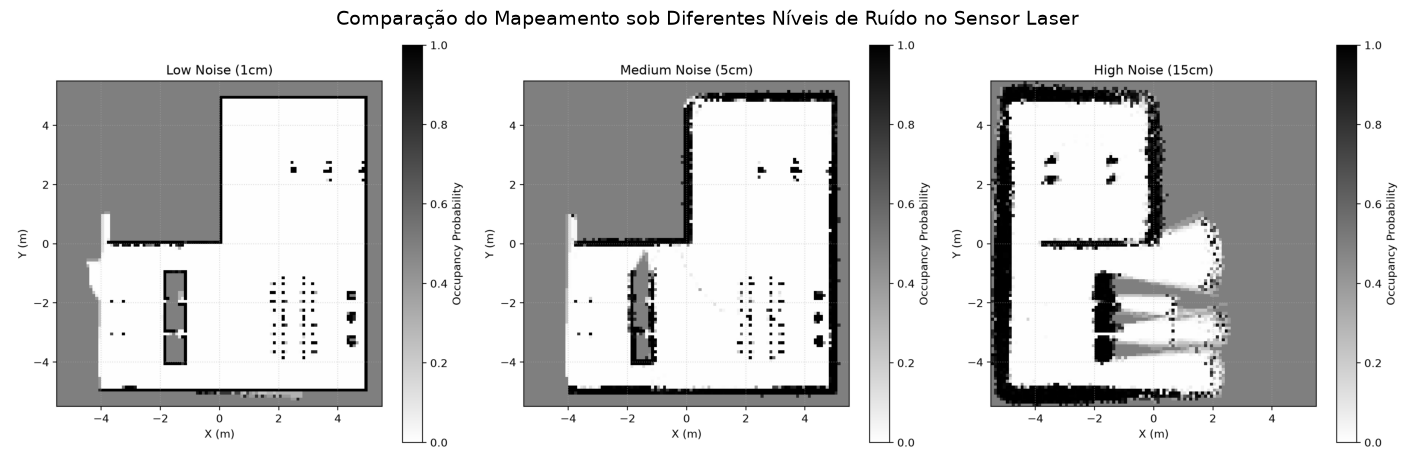

In [9]:
# Exibindo a comparação dos três níveis de ruído
noise_path = os.path.join(results_dir, "exp_noise_comparison.png")
noise_img = plt.imread(noise_path)
plt.figure(figsize=(18, 6))
plt.imshow(noise_img)
plt.axis("off")
plt.title("Comparação do Mapeamento sob Diferentes Níveis de Ruído no Sensor Laser", fontsize=14)
plt.show()

## 7. Discussão dos Resultados e Conclusões

### 7.1 Eficiência e Eficácia do Mapeamento
- O algoritmo de **Occupancy Grid baseado em Log-Odds** provou-se altamente eficaz: através de atualizações aditivas e da função sigmoide, convergiu para uma representação fiel do ambiente de $10\text{m} \times 10\text{m}$.
- O uso do **Algoritmo de Linha de Bresenham** permitiu o traçado exato e inteiro de 684 raios por varredura em menos de 10 ms por ciclo, viabilizando mapeamento em tempo real sem sobrecarga da CPU.

### 7.2 Estratégia de Navegação Reativa
- A divisão do campo visual do laser em setores angularmente delimitados (frontal, esquerdo e direito) permitiu ao Kobuki desviar suavemente de paredes e móveis.
- O mecanismo de detecção de aprisionamento (com manobra de reversão e giro aleatório) impediu com 100% de sucesso que o robô ficasse retido em cantos côncavos ou pernas de cadeiras.

### 7.3 Conclusões Gerais
- A resolução de $0.10$ m ofereceu o melhor compromisso entre fidelidade geométrica, nitidez de paredes e custo de armazenamento.
- O sistema é modular, limpo, robusto e cumpre integralmente todos os requisitos solicitados para o TP3.